# Predicción del costo de vivienda en la Zona Metropolitana de la Ciudad de México

En este proyecto lo que se buscara sera estimar el precio anunciado de una casa a partir de sus caracterisitcas fisicas, uncación y entorno urbano. Los datos seleccionados son 6,800 registros de casas en venta, correspondientes a abril de 2026, con 99 columnas en el dataset original, los cuales se provienen de forma publica del sitio de Datos Abiertos del **Observatorio Urbano de Valores** https://ouv.com.mx/index

### Planteamiento del Problema

Bien, lo que buscamos respondernos es lo siguiente: ¿Qué tan bien podemos estimar el precio anunciado de una casa en la Zona Metropolitana del Valle de México utilizando sus características y su contexto urbano?, para ello pondremos a prueba diferentes metodologías de predicción para definir la más certera.

Las hipótesis que tenemos planteadas hasta el momento son las siguientes: 

| Hipótesis | Cómo la evaluaremos |
| :--- | :--- |
| Una mayor superficie construida se relaciona con precios más altos. | Análisis exploratorio y modelos |
| La ubicación aporta información predictiva relevante. | Comparación de modelos |
| Las variables de accesibilidad urbana mejoran la estimación. | Modelo base frente a modelo ampliado |
| Los errores aumentan en viviendas de precios elevados. | Análisis de errores por rangos |

**Notas Metodologicas del Alcance del Proyecto:**

- Solo casas, no departamentos.
- Solo ofertas de venta de abril de 2026.
- Cobertura de Ciudad de México, Estado de México e Hidalgo, según la muestra disponible.
- El objetivo es estimar precios anunciados, no precios finales de compraventa.
- Los resultados no deben interpretarse como una valuación profesional ni como una estimación de precios actuales fuera del periodo estudiado.

## Codigo

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
# Aqui esta el dataset de Abril 2026 para la Zona Metropolitana de la Ciudad de México
df26 = gpd.read_file("zmcm_casas_abr26.gpkg")

In [2]:
print("Dimensiones:", df26.shape)
print("\nTipo de Datos")
print(df26.dtypes.value_counts())
print("\nValores Faltantes por Columna")
print(df26.isna().sum().sort_values(ascending=False))
print("\nRegistros Duplicados")
print(df26.duplicated().sum())
print(df26.isna().sum().sort_values(ascending=False))
print("\nNumero de IDs  Unicos")
print(df26['id'].nunique())

Dimensiones: (6800, 99)

Tipo de Datos
float64     83
object       8
int32        7
geometry     1
Name: count, dtype: int64

Valores Faltantes por Columna
id                                                             0
lat                                                            0
lon                                                            0
tipo                                                           0
modalidad                                                      0
                                                              ..
e2sfca_total                                                   0
e2sfca_areas_verdes_deporte_y_recreacion_del_sector_publico    0
Dist_DCN                                                       0
Submercado                                                     0
geometry                                                       0
Length: 99, dtype: int64

Registros Duplicados
0
id                                                             0
lat            

Bien, ya tenemos la base cargada, ya revisamos que los ID si sean todos unicos, el tipo de datos de nuestras columnas y nos aseguramos de que no hay registros duplicados. Ahora lo que haremos sera validar que los datos sean consistentes, hay que recordar que el hecho de que no haya valores nulos no descarta la posibilidad de que haya algun valor absurdo que se haya ingresado erroneamente

In [3]:
columnas= ["precio", "precio_m2","banos", "m2_construidos", 
           "m2_terreno","estacionamiento","antiguedad","lat", "lon"]

In [4]:
print(df26[columnas].describe().T.round(2))

                  count        mean         std        min         25%  \
precio           6800.0  7654308.71  8247784.50  350000.00  2300000.00   
precio_m2        6800.0    25965.57    15014.46     934.90    15073.50   
banos            6800.0        2.57        1.19       0.00        2.00   
m2_construidos   6800.0      262.92      172.18      45.00      144.00   
m2_terreno       6800.0      242.70      203.35      45.00      120.00   
estacionamiento  6800.0        2.43        1.31       1.00        1.00   
antiguedad       6800.0       17.27       15.86       1.00        1.00   
lat              6800.0       19.46        0.15      19.05       19.33   
lon              6800.0      -99.14        0.11     -99.41      -99.23   

                        50%         75%          max  
precio           4972500.00  9900000.00  60000000.00  
precio_m2          23391.81    33517.49    118556.70  
banos                  2.00        3.00         6.00  
m2_construidos       220.00      343.00

In [5]:
print('\nVariables Categoricas:')
for col in ["tipo", "modalidad", "moneda", "periodo",
            "NOM_ENT", "Submercado"]:
    print(f'\n{col}:')
    print(df26[col].value_counts(dropna=False))


Variables Categoricas:

tipo:
tipo
Casa    6800
Name: count, dtype: int64

modalidad:
modalidad
Venta    6800
Name: count, dtype: int64

moneda:
moneda
MXN    6776
USD      24
Name: count, dtype: int64

periodo:
periodo
abril26    6800
Name: count, dtype: int64

NOM_ENT:
NOM_ENT
México              3553
Ciudad de México    3133
Hidalgo              114
Name: count, dtype: int64

Submercado:
Submercado
1    1715
3    1635
4    1597
5    1089
0     659
2     105
Name: count, dtype: int64


Primero, hay 24 registros de casas con valores en USD, esto lo vamos a cambiar dado que queremos que todo se refleje en pesos mexicanos.
    Segundo, las clases de Submercado  tienen un ligero desbalance en las categorias 0 y 2.

Además en la tabla anterior encontramos que hay al menos un registro con 0 baños, eso tambien es algo que vamos a supervisar. 

In [6]:
usd=df26[df26['moneda']== 'USD' ]

print("Registros en USD:", len(usd))
print(usd[["id", "precio", "precio_m2",
           "NOM_ENT", "NOM_MUN"]].head(5))

Registros en USD: 24
            id      precio      precio_m2           NOM_ENT         NOM_MUN
315   30257789  57255000.0  104100.000000  Ciudad de México  Álvaro Obregón
338   28868165  44936500.0   87595.516569  Ciudad de México  Álvaro Obregón
412   15237316   1561500.0    7654.411765            México    Chimalhuacán
2067  31011003  52050000.0   81201.248050  Ciudad de México  Álvaro Obregón
2299  29497852  39905000.0   66508.333333  Ciudad de México  Miguel Hidalgo


Lo que estamos haciendo es evaluar si las propiedades en USD realmente estan en ese valor o fue un error al expresar la moneda y realmente estan en pesos mexicanos

In [7]:
print(
    df26.loc[
        df26["moneda"] == "USD",
        ["id", "precio", "precio_m2", "m2_construidos",
         "m2_terreno", "NOM_ENT", "NOM_MUN"]
    ].to_string(index=False)
)

      id     precio     precio_m2  m2_construidos  m2_terreno          NOM_ENT               NOM_MUN
30257789 57255000.0 104100.000000             550        1000 Ciudad de México        Álvaro Obregón
28868165 44936500.0  87595.516569             513         625 Ciudad de México        Álvaro Obregón
15237316  1561500.0   7654.411765             204         204           México          Chimalhuacán
31011003 52050000.0  81201.248050             641         761 Ciudad de México        Álvaro Obregón
29497852 39905000.0  66508.333333             600        1175 Ciudad de México        Miguel Hidalgo
28738065 41640000.0  41640.000000            1000        1100           México   Naucalpan de Juárez
29964228 31230000.0  69400.000000             450        1193           México   Naucalpan de Juárez
30387257 29495000.0  60814.432990             485         405 Ciudad de México        Miguel Hidalgo
30977207 48580000.0  68810.198300             706         894 Ciudad de México        Álvar

Hasta ahora parece que realmente estan en pesos mexicanos, el tamaño de la vivienda parece corresponder con el valor de la casa aqui en México

In [8]:
columnas = [
    "precio", "precio_m2", "banos",
    "m2_construidos", "m2_terreno",
    "estacionamiento", "antiguedad",
    "lat", "lon"
]

print(df26[columnas].describe().T.round(2))

print("\nValores negativos:")
for col in columnas:
    print(f"{col}: {(df26[col] < 0).sum()}")

                  count        mean         std        min         25%  \
precio           6800.0  7654308.71  8247784.50  350000.00  2300000.00   
precio_m2        6800.0    25965.57    15014.46     934.90    15073.50   
banos            6800.0        2.57        1.19       0.00        2.00   
m2_construidos   6800.0      262.92      172.18      45.00      144.00   
m2_terreno       6800.0      242.70      203.35      45.00      120.00   
estacionamiento  6800.0        2.43        1.31       1.00        1.00   
antiguedad       6800.0       17.27       15.86       1.00        1.00   
lat              6800.0       19.46        0.15      19.05       19.33   
lon              6800.0      -99.14        0.11     -99.41      -99.23   

                        50%         75%          max  
precio           4972500.00  9900000.00  60000000.00  
precio_m2          23391.81    33517.49    118556.70  
banos                  2.00        3.00         6.00  
m2_construidos       220.00      343.00

Ahora vamos a ver que sucede con el o los registros que tienen 0 baños

In [9]:
print("Casas con cero baños:")
print(
    df26.loc[
        df26["banos"] == 0,
        ["id", "precio", "banos", "m2_construidos",
         "m2_terreno", "NOM_ENT", "NOM_MUN"]
    ].to_string(index=False)
)

Casas con cero baños:
      id     precio  banos  m2_construidos  m2_terreno          NOM_ENT                 NOM_MUN
29388420  4978400.0      0             205         159 Ciudad de México              Cuauhtémoc
26382096  1400000.0      0             244         186           México      Cuautitlán Izcalli
30637499  3600000.0      0              90         140           México     Ecatepec de Morelos
29737998  1400000.0      0             180         210           México      Cuautitlán Izcalli
30346492  6680000.0      0             300        1112           México             Teotihuacán
30843126  3070000.0      0             249         132 Ciudad de México              Iztapalapa
26786039  5200000.0      0             205         166 Ciudad de México              Iztapalapa
30387227   900000.0      0              63          63           México     Ecatepec de Morelos
28593667 16500000.0      0             487         312 Ciudad de México  La Magdalena Contreras
29316146 12500000.

In [10]:
print("Casas con cero baños:",
      (df26["banos"] == 0).sum())

print("Porcentaje de casas con cero baños:",
      round((df26["banos"] == 0).mean() * 100, 2), "%")

Casas con cero baños: 47
Porcentaje de casas con cero baños: 0.69 %


Bien, son 47, realmente son muy pocos los registros

In [11]:
#Registros que cumplen al menos una de las 2 condiciones
filtro= (df26['moneda']=='USD') | (df26['banos']==0 )
print('Registros en USD y/o con 0 banios:' , filtro.sum())

# Desglose de cada condición
print("Registros en USD:", (df26["moneda"] == "USD").sum())
print("Registros con 0 baños:", (df26["banos"] == 0).sum())

# Registros que cumplen ambas condiciones
print("Registros en USD y con 0 baños:",
      ((df26["moneda"] == "USD") & (df26["banos"] == 0)).sum())

Registros en USD y/o con 0 banios: 71
Registros en USD: 24
Registros con 0 baños: 47
Registros en USD y con 0 baños: 0


Al ser 71 registros y consultar la información disponible en el sitio de Observatorio Urbano de Valores no encontramos información que nos condujera a que significa que una casa este marcada con 0 baños (dado que asumimos que realmente no hay casas que no tengan al menos uno) y como el sitio hace uso de web scrapping para obtener los precios de vivienda, tampoco tenemos forma de asegurar que los valores en USD esten correctos o incorrectos. El total de estos casos solo representan el 1.04% de la muestra, por lo que, al menos para facilidad de este ejercicio vamos a descartar esos valores momentaneamente

In [12]:
# Excluir registros con moneda USD o cero baños
df_modelo = df26.loc[~filtro].copy()

print("Registros originales:", len(df26))
print("Registros excluidos:", filtro.sum())
print("Registros restantes:", len(df_modelo))
print("Porcentaje conservado:",
      round(len(df_modelo) / len(df26) * 100, 2), "%")

Registros originales: 6800
Registros excluidos: 71
Registros restantes: 6729
Porcentaje conservado: 98.96 %


# Base Depurada

In [13]:
print('Dimensiones', df_modelo.shape)
print('\n Valores Faltantes:', df_modelo.isna().sum().sum())
print('\n Valores Duplicados:', df_modelo.duplicated().sum())
print("\nDistribución de moneda:")
print(df_modelo["moneda"].value_counts())
print("\nMínimo de baños:", df_modelo["banos"].min())

Dimensiones (6729, 99)

 Valores Faltantes: 0

 Valores Duplicados: 0

Distribución de moneda:
moneda
MXN    6729
Name: count, dtype: int64

Mínimo de baños: 1


Listo, no tenemos valores faltantes, tampoco duplicados, todo esta en pesos mexicanos y además el numero minimo de baños es 1

# Análisis Exploratorio de Datos

La variable objetivo con la que vamos a trabajar es el **precio**, vamos a entender algunos de sus elementos, como su distribucion, su dispersion y la presencia de outliers

In [14]:
#Librerias de graficado
import matplotlib.pyplot as plt
import seaborn as sns

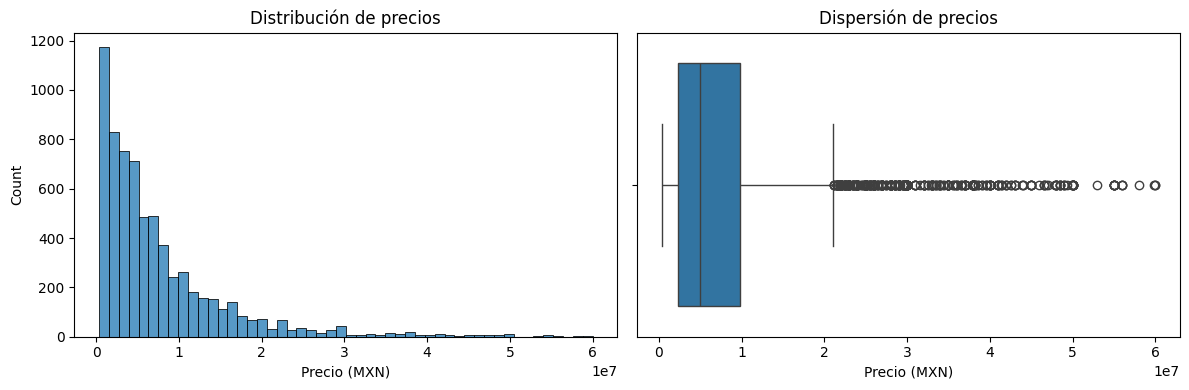

In [15]:
#Plot 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df_modelo, x="precio", bins=50, ax=axes[0])

axes[0].set_title("Distribución de precios")
axes[0].set_xlabel("Precio (MXN)")

sns.boxplot(data=df_modelo,x="precio",ax=axes[1])

axes[1].set_title("Dispersión de precios")
axes[1].set_xlabel("Precio (MXN)")

plt.tight_layout()
plt.show()

Bien, el histograma tiene un eje X que expresa 10 millones por cada unidad en la grafica, estos nos dice que la mayoria de las casas estan concentradas en valores menores a 20 millones de pessos.

El Box plot nos dice que hay muchos valores atipicos, esto hace sentido cuando lo pones a lado del histograma, ya que aunque hay pocos valores apartir de los 20M la realidad es que soin suficientes para arrastrar la cola del histograma a la derecha y ser visibles en la grafica, lo que podriamos intentar sería realizar una transformacion logaritmica, pero antes de eso vamos a calcular sus estadisticas y el umbral estadístico de valores atípicos mediante el rango intercuartíl (IQR)

In [16]:
precio= df_modelo['precio']

q1=precio.quantile(.25)
q3=precio.quantile(.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

In [17]:
print('Media', round(precio.mean(), 2))
print('Mediana', round(precio.median(), 2))
print("Asimetría:", round(precio.skew(), 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("Límite superior IQR:", round(limite_superior, 2))
print("Observaciones por encima del límite:", (precio > limite_superior).sum())

Media 7565821.72
Mediana 4950000.0
Asimetría: 2.43
Q1: 2300000.0
Q3: 9800000.0
Límite superior IQR: 21050000.0
Observaciones por encima del límite: 421


Podemos ver como el promedio del valor de las casas aumenta considerablemente con respecto a la mediana, pero seguramente se debe tambien a las casas con preciosmuy altos. 

Tener 421 observaciones por encima del limite, es decir un 6.3% es un valor realtivamente alto para valores atipicos

Primero estudiaremos la relación que pareciera ser la más obvia, es decir, la del precio de la vivienda con la supercicie construida

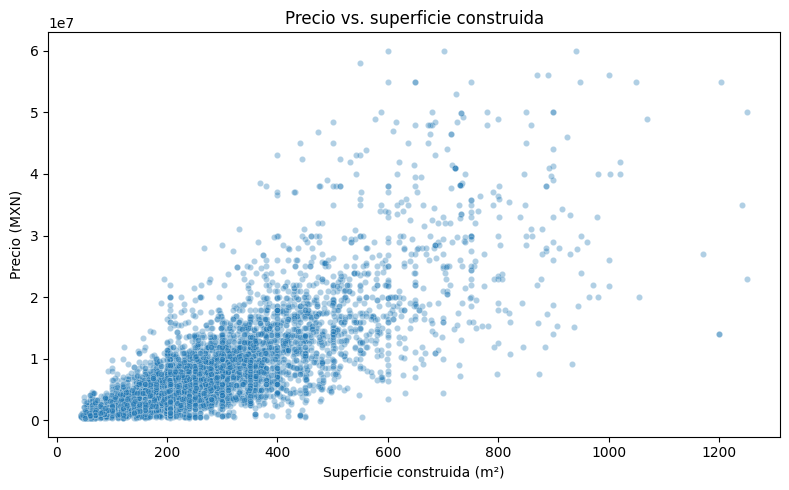

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_modelo, x="m2_construidos", y="precio", alpha=0.35, s=20)

plt.title("Precio vs. superficie construida")
plt.xlabel("Superficie construida (m²)")
plt.ylabel("Precio (MXN)")
plt.tight_layout()
plt.show()

Esta grafica parece indicar que si hay una correlacion entre el precio de la vivienda y la superficie construida, de igual forma lo vamos a corroborar con la correlacion de Pearson

In [19]:
print(df_modelo[["precio", "m2_construidos", "m2_terreno"]].corr().round(3))

                precio  m2_construidos  m2_terreno
precio           1.000           0.794       0.696
m2_construidos   0.794           1.000       0.720
m2_terreno       0.696           0.720       1.000


Bien esta matriz nos dice que si hay una fuerte correlación para ambas variables, es decir que a mayor precio mayor seran metros cuadrados construidos y que a mayor precio mayor metros cuadrados tiene el terreno, esto por si solo no nos dice mucho. 

Dado que tenemos muchas variabnles numericas e ir analizando una por una no agregaría mucho valor al análisis, vamos a proceder a realizar un mapa de calor que nos muestre la correlación de la variable objetivo con todas las variables numericas

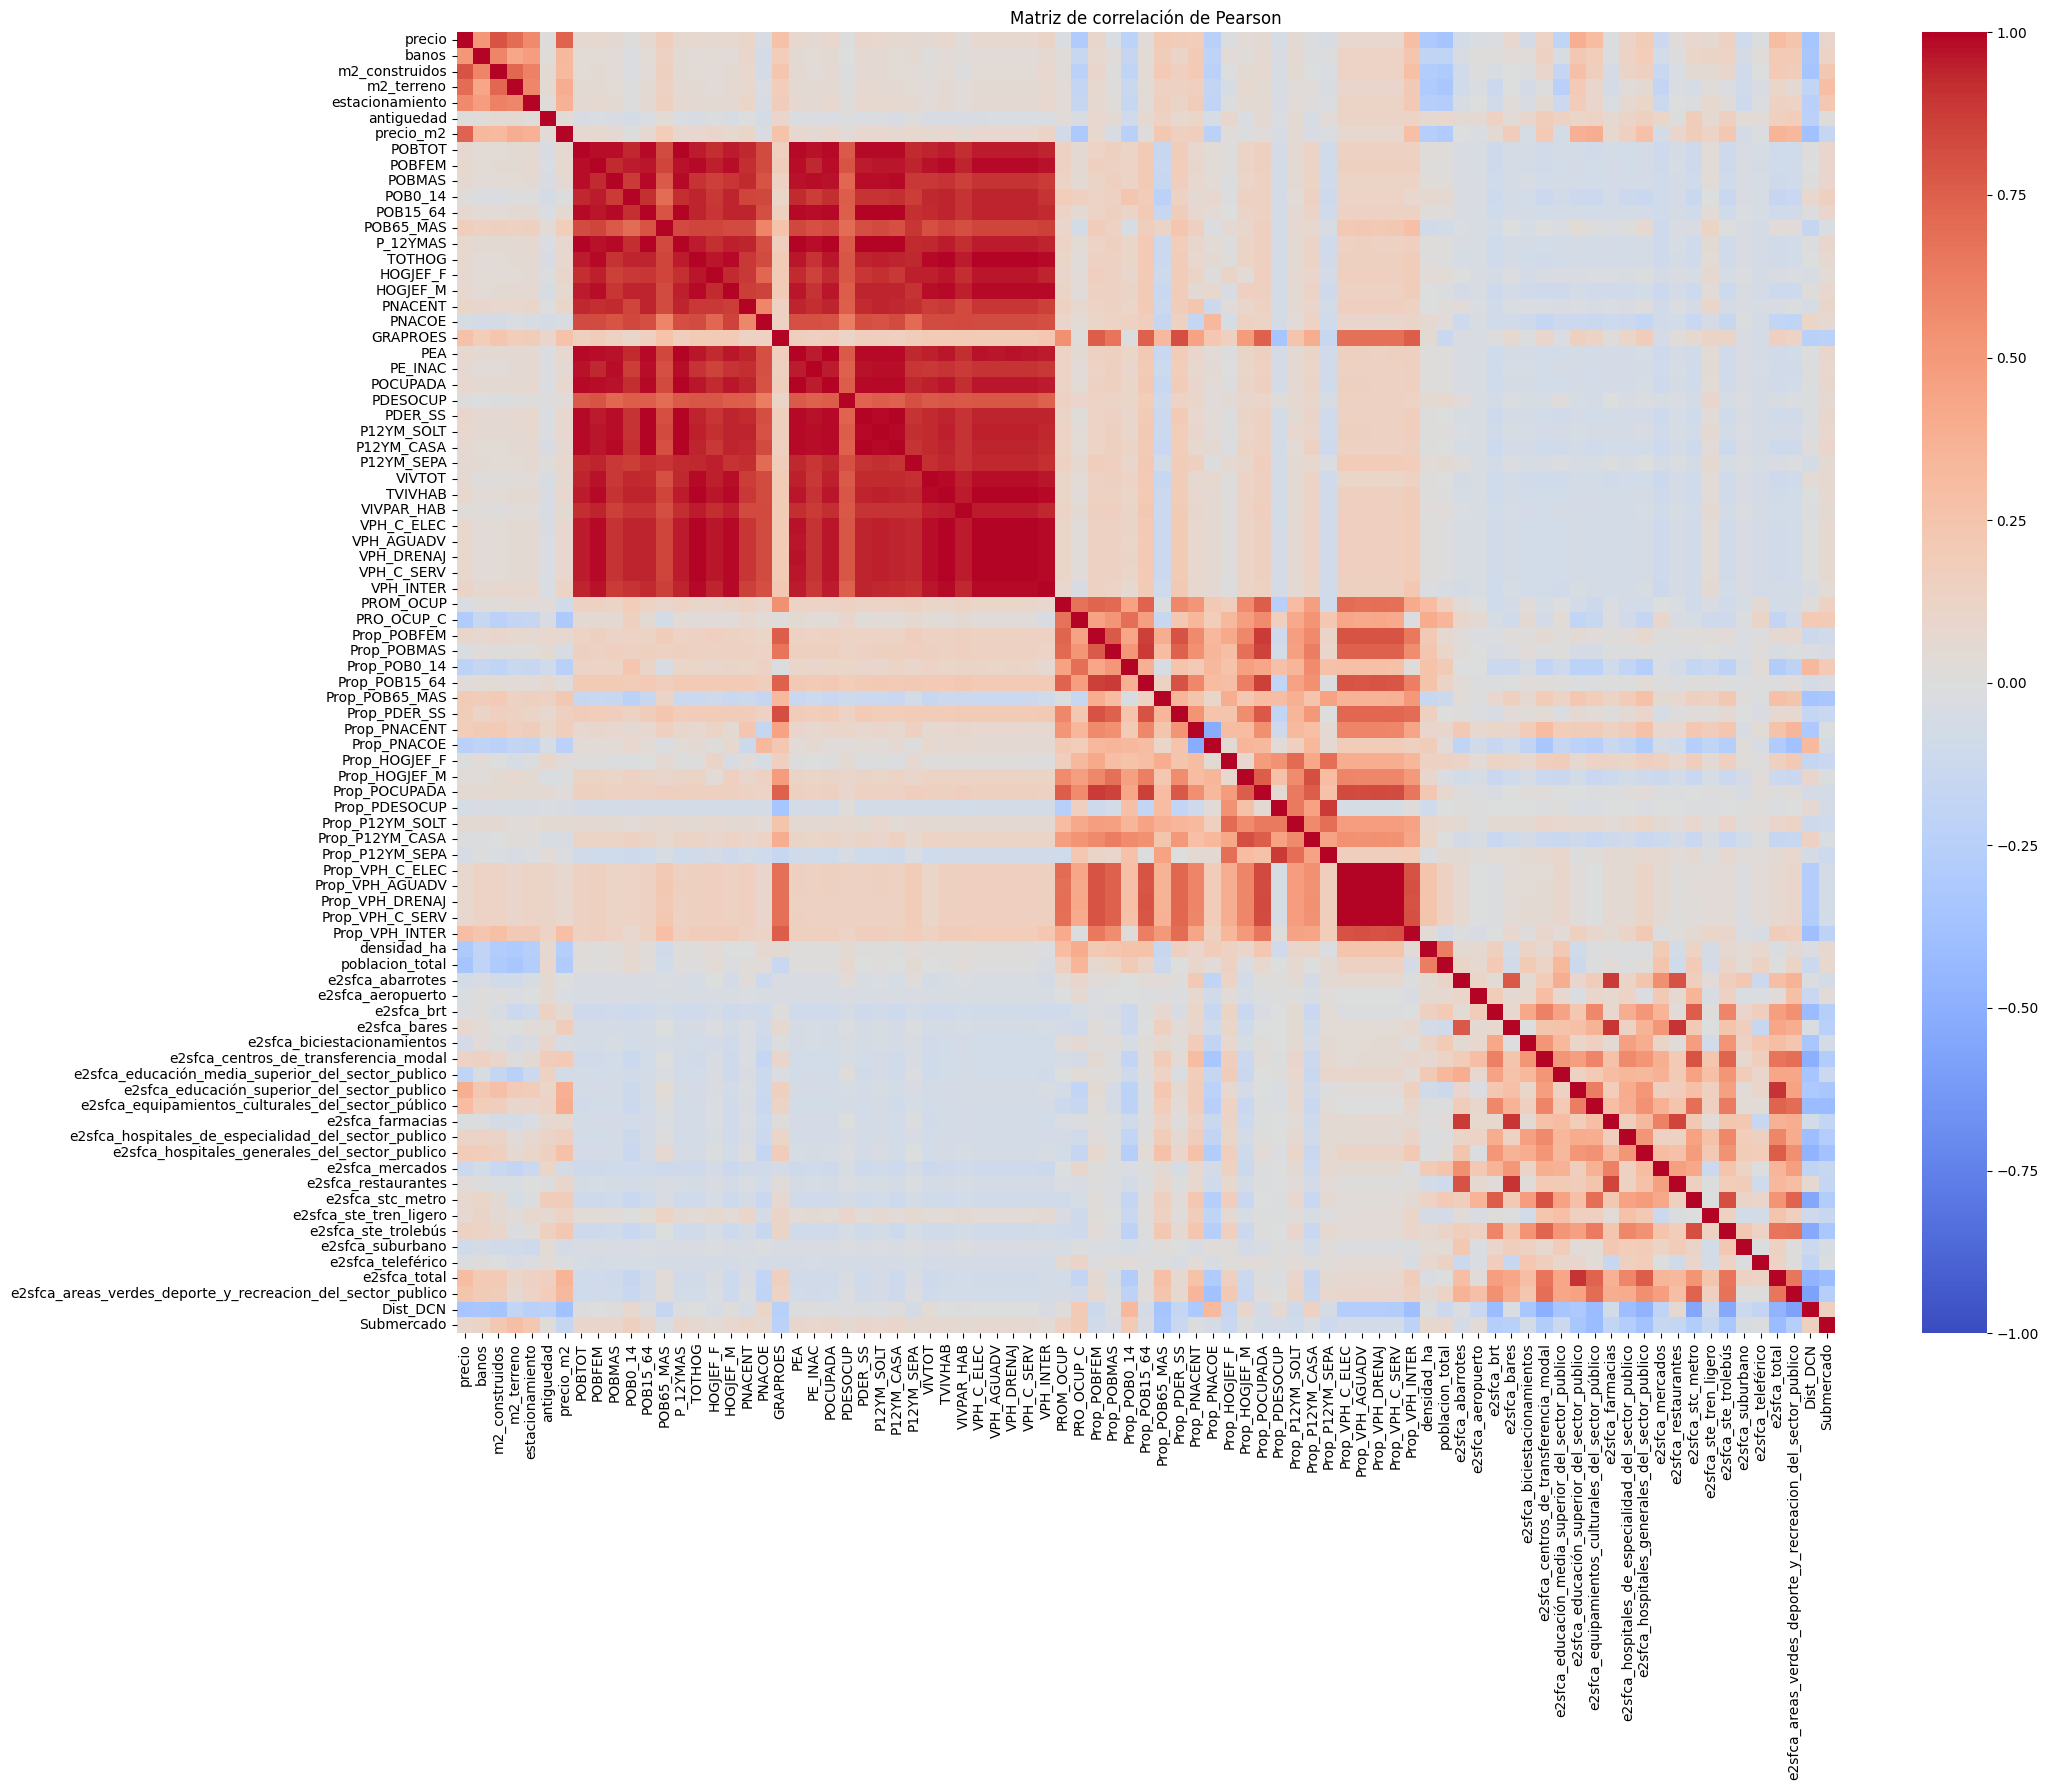

In [20]:
# Seleccionar variables numéricas
df_corr = df_modelo.select_dtypes(include="number").copy()

# Excluir identificadores y variables redundantes o derivadas
excluir = ["id", "lat", "lon", "AGEB", "MZA", "hex_id", "area_m2", "area_ha"]

df_corr = df_corr.drop(
    columns=excluir,
    errors="ignore"
)

# Matriz de correlación
corr = df_corr.corr(method="pearson")

# Correlograma
plt.figure(figsize=(22, 18))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

Bueno, es claro que el correlograma es dificil de leer dado que son muchas variables (83) por lo que vamos a buscar qudarnos con las variable que muestren mayor correlación

In [21]:
corr_precio = (corr["precio"].drop(["precio", "precio_m2"], errors="ignore").dropna()
    .sort_values(key=abs, ascending=False)
)

corr_precio.head(15)

m2_construidos                                                 0.794081
m2_terreno                                                     0.695966
estacionamiento                                                0.576555
banos                                                          0.508842
e2sfca_educación_superior_del_sector_publico                   0.386427
poblacion_total                                               -0.353217
Dist_DCN                                                      -0.347483
densidad_ha                                                   -0.311469
e2sfca_equipamientos_culturales_del_sector_público             0.310313
e2sfca_total                                                   0.300653
PRO_OCUP_C                                                    -0.296400
Prop_VPH_INTER                                                 0.291316
GRAPROES                                                       0.267269
e2sfca_areas_verdes_deporte_y_recreacion_del_sector_publico    0

Primero quiero observar que no haya fuerte colinealidad entre las dos primeras variables, de ser así me quedaría solo con una

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
variables = ["m2_construidos", "m2_terreno"]

X = df_modelo[variables].dropna()

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif

,variable,VIF
0,m2_construidos,2.07425
1,m2_terreno,2.07425


El factor de inflación de la varianza (VIF) se encuentras un indicador estadístico que mide cuánto aumenta la varianza de los coeficientes de un modelo de regresión debido a la relación entre sus variables predictoras, es decir, nos ayuda a identificar si dos o más variables contiene información demsadio similar, en un rango entre 1 y 5 se considera manejable, por lo cual, podemos seguir manteniendo ambas variables por ahora.

Bien, ahora, vamos a realizar 3 gruposde variables: 

- **Características del inmueble:** superficies, estacionamiento y baños.
- **Accesibilidad urbana:** educación superior, equipamientos culturales, accesibilidad total y áreas verdes.
- **Contexto urbano y sociodemográfico:** población, distancia al centro, densidad y las variables demográficas restantes.

### Variables Fisicas del Inmueble

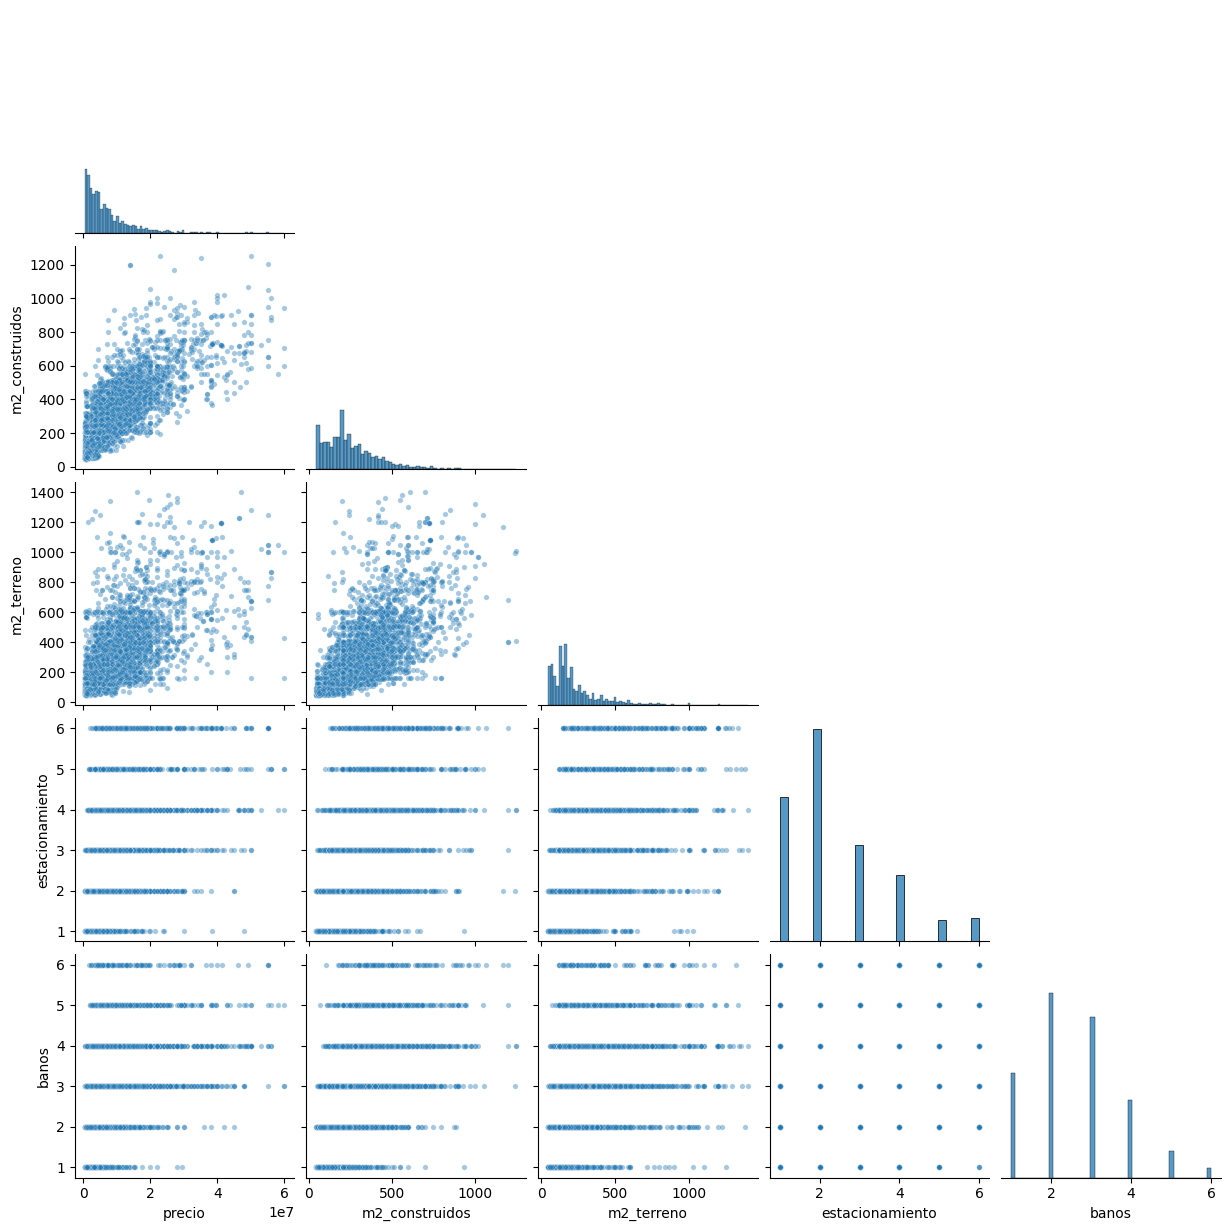

In [23]:
variables_inmueble = [
    "precio",
    "m2_construidos",
    "m2_terreno",
    "estacionamiento",
    "banos"
]

sns.pairplot(
    df_modelo[variables_inmueble].dropna(),
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.4, "s": 15}
)

plt.show()

In [24]:
df_modelo[["precio", "m2_construidos", "m2_terreno"]
    ].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T.round(2)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
precio,6729.0,7565821.72,8063079.42,350000.0,2300000.0,4950000.0,9800000.0,17000000.0,23500000.0,41000000.00,60000000.0
m2_construidos,6729.0,261.27,170.15,45.0,143.0,220.0,340.0,480.2,600.0,850.00,1250.0
m2_terreno,6729.0,240.77,200.59,45.0,120.0,170.0,297.0,500.0,657.2,1029.72,1400.0


Podemos ver por los valores de la tabla anterior que las casas con valores elevados provocan que las variables tengan comportamientos asimetricos cuando se grafica, mientras que el promerio del precio de las casas es de 7.5 M su mediana es de 4.95 M,y que mientras los metros cuardados construidos y de superficio del terreno tienen medias que se ven superadas por la mediana de forma muy brusca 

Antes de tomar la decision de borrar los registros atipicos, hay que ver como se visualizan los datos con una escala logaritmica

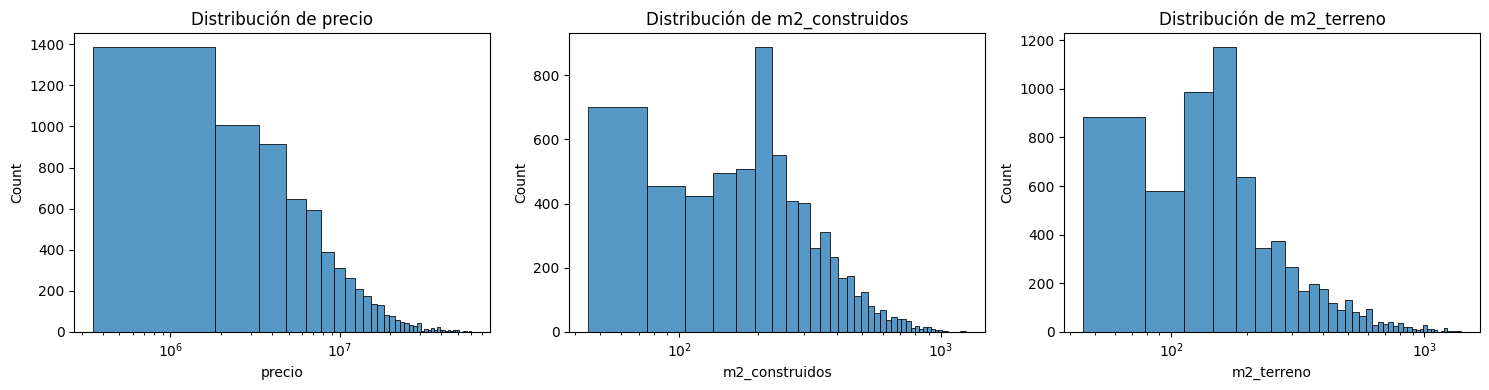

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

variables = ["precio", "m2_construidos", "m2_terreno"]

for ax, col in zip(axes, variables):
    sns.histplot(df_modelo[col], bins=40, ax=ax)
    ax.set_xscale("log")
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

Los histogramas confirman que las tres variables tienen distribuciones asimétricas hacia la derecha, aunque con algunas diferencias

### Variables de Accesibilidad Urbana

In [26]:
#Cambiamos los nombres de las variables para que sean más legibles
nombres = {"precio": "Precio",
    "e2sfca_educación_superior_del_sector_publico": "Educación superior",
    "e2sfca_equipamientos_culturales_del_sector_público": "Equipamientos culturales",
    "e2sfca_total": "Accesibilidad total",
    "e2sfca_areas_verdes_deporte_y_recreacion_del_sector_publico": "Áreas verdes y recreación"}

In [27]:
df_plot = df_modelo[list(nombres.keys())].rename(columns=nombres)

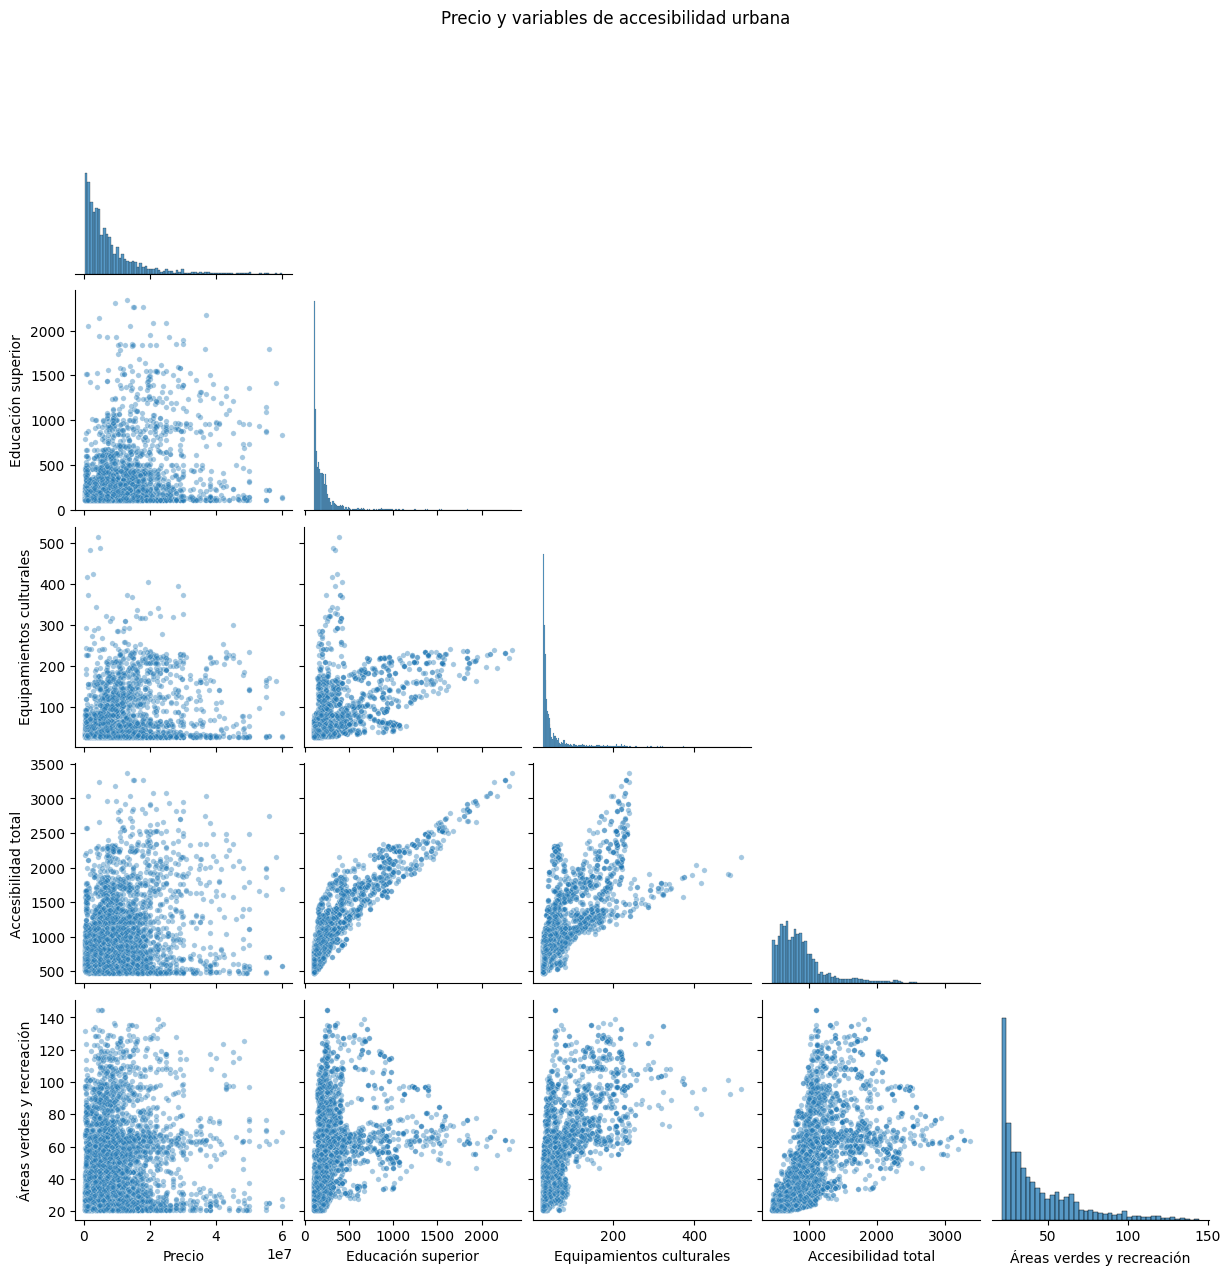

In [28]:
g= sns.pairplot( df_plot.dropna(),diag_kind="hist", corner=True, plot_kws={"alpha": 0.4, "s": 15})
g.fig.suptitle( "Precio y variables de accesibilidad urbana", y=1.02)

plt.show()

Se puede notar una relacion positica entre Educacion superior y Accesabilidad total, Equipamientos Culturales, entre Equipamientos y Accesabilidad y Accesabilidad Roral con Áreas verdad y recreacion

Ahora, realizaremos una matriz de relacion para corroborar que no haya redundancia entre los indicadores

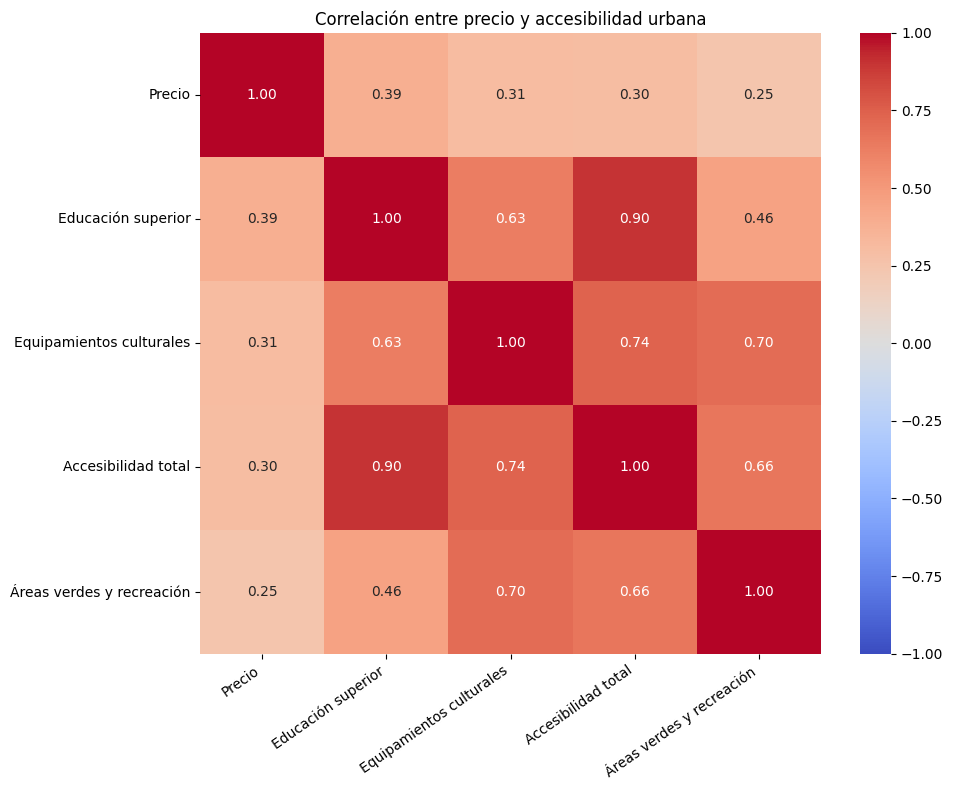

In [29]:
# Seleccionar y renombrar columnas
df_corr = df_modelo[list(nombres.keys())].rename(columns=nombres)

# Calcular correlaciones
corr_accesibilidad = df_corr.corr(method="pearson")

# Graficar
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_accesibilidad,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre precio y accesibilidad urbana")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

En el correlograma se ve ahora más marcado lo anterior

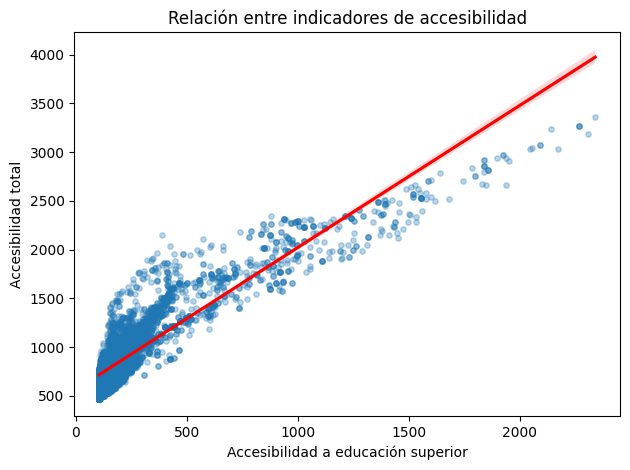

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(
    data=df_modelo,
    x="e2sfca_educación_superior_del_sector_publico",
    y="e2sfca_total",
    scatter_kws={"alpha": 0.3, "s": 15},
    line_kws={"color": "red"}
)

plt.xlabel("Accesibilidad a educación superior")
plt.ylabel("Accesibilidad total")
plt.title("Relación entre indicadores de accesibilidad")
plt.tight_layout()
plt.show()

Esta grafica parece confirmar lo anterior, parece que entre ambas vairables hay redundancia estadisitca

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

variables = [
    "e2sfca_educación_superior_del_sector_publico",
    'e2sfca_equipamientos_culturales_del_sector_público',
    "e2sfca_total",
    "e2sfca_areas_verdes_deporte_y_recreacion_del_sector_publico"
]

X = df_modelo[variables].dropna()

resultados_vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

resultados_vif.sort_values("VIF", ascending=False)

,variable,VIF
2,e2sfca_total,9.274265
0,e2sfca_educación_superior_del_sector_publico,6.307290
1,e2sfca_equipamientos_culturales_del_sector_púb...,2.691006
3,e2sfca_areas_verdes_deporte_y_recreacion_del_s...,2.512862


Con el Variation Inflationn Factor corrorboraamos nuevamente que hay redundancia estadistica entre ambas variables, como no tenemos forma de corroborar lo anotaremos en las hallazgos más adelante

### Variables Sociodemograficas

Nos vamos a quedar con alguans de las variables de cada una de los grupos

In [32]:
# Cambiamos los nombres para hacerlo más legible
variables_urbanas = {
    "precio": "Precio",
    "poblacion_total": "Población total",
    "Dist_DCN": "Distancia al centro",
    "densidad_ha": "Densidad (hab./ha)",
    "PRO_OCUP_C": "Promedio de ocupantes"
}

In [33]:
df_plot = df_modelo[list(variables_urbanas.keys())].rename(columns=variables_urbanas)

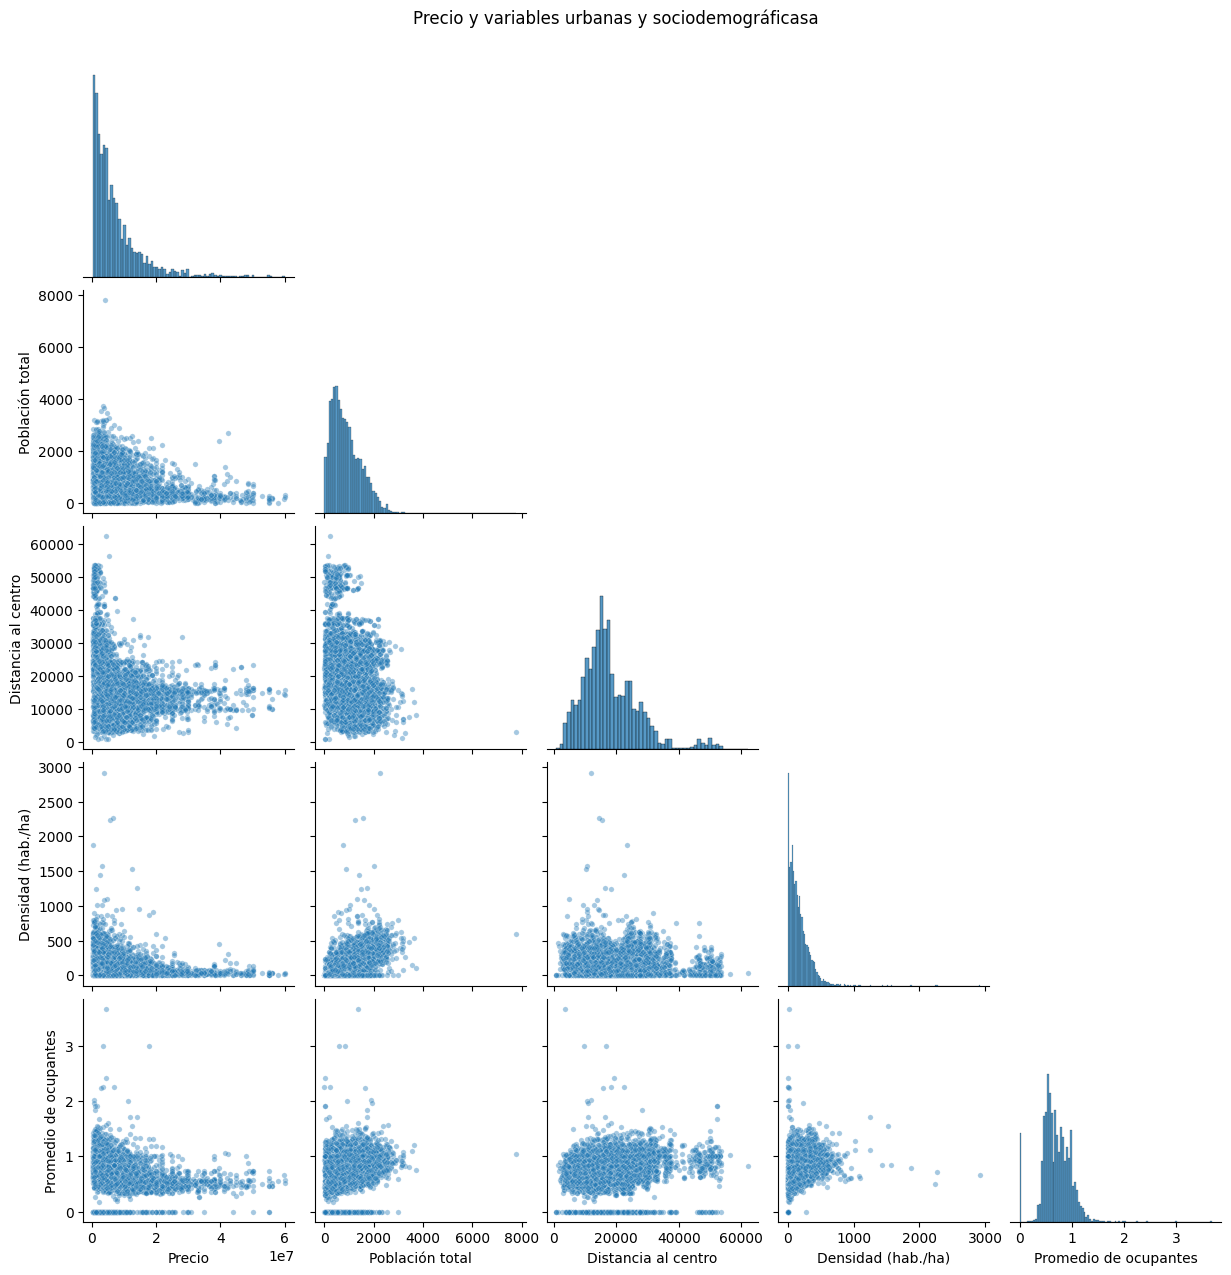

In [34]:
g= sns.pairplot( df_plot.dropna(),diag_kind="hist", corner=True, plot_kws={"alpha": 0.4, "s": 15})
g.fig.suptitle( "Precio y variables urbanas y sociodemográficasa", y=1.02)

plt.show()

A diferencia del anterior grupo de variables en esta no considero que sea vea una relación marcada entre variables, si bien hay variables que tienen una asoacioan negativa con el precio (como poblaciony distancia al centro) no parece haber una relacion lineal simple. Al igual que con el grupo de variables anteriores vamos a realizar un correlograma para ver la correlación de estas variables

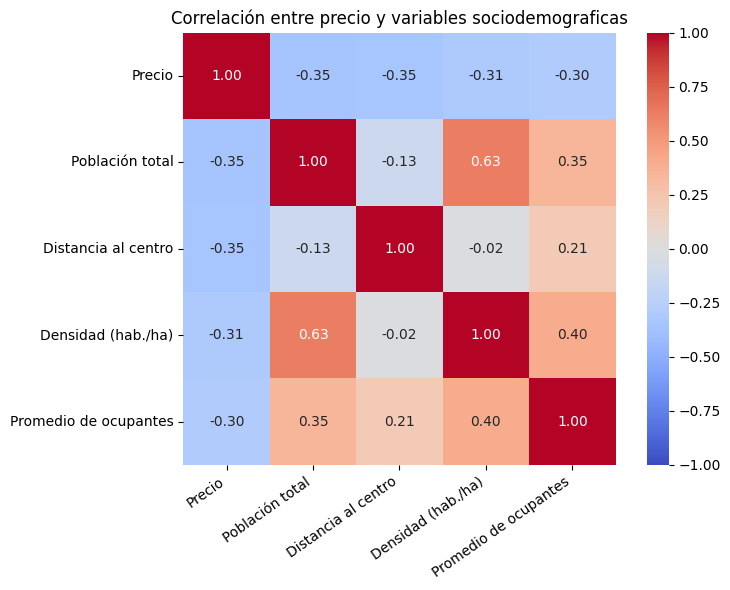

In [35]:
# Seleccionar y renombrar columnas
df_corr = df_modelo[list(variables_urbanas.keys())].rename(columns=variables_urbanas)

# Calcular correlaciones
corr_accesibilidad = df_corr.corr(method="pearson")

# Graficar
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_accesibilidad,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre precio y variables sociodemograficas")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Bien, de este correlograma creo que solo podemos llevarnos que existe una fuerte correlación entre la población total y l adensidad. Pareciera ser que las variables sociodemograficas no tienen un impacto fuerte en la variable precio

#### Resumen

De momento la unica variable que muestra una correlaicón alta son los metrozss construidos, seguida de los metros del terreno. Si bien hay variables que tienen fuerte correlación entre si, no lo tienen con la variable objetivo (como educacion superiror y accesabilidad urbana), esto lo documentaremos al final, además de temrinar de realizar un análisis de estas variables ahora de forma no lineal por si hay alguna que sigue manteniendo correlación con la variable objetivo.

### Correlación de Spearman

Vamos a analizar si la correlación de Spearmnan (no lineal) es mayor que la de Pearson y sobre que variables lo es.

In [36]:
variables = [
    "precio",
    "m2_construidos",
    "m2_terreno",
    "estacionamiento",
    "banos",
    "Dist_DCN",
    "densidad_ha",
    "poblacion_total",
    "e2sfca_educación_superior_del_sector_publico",
    "e2sfca_total"]

In [37]:
# Correlación con el precio
comparacion = pd.DataFrame({
    "Pearson": df_modelo[variables].corr(method="pearson")["precio"],
    "Spearman": df_modelo[variables].corr(method="spearman")["precio"]}).drop(index="precio")

comparacion["Diferencia_abs"] = (comparacion["Spearman"] - comparacion["Pearson"]).abs()

comparacion.sort_values("Diferencia_abs", ascending=False).round(3)

,Pearson,Spearman,Diferencia_abs
Dist_DCN,-0.347,-0.508,0.161
banos,0.509,0.638,0.129
estacionamiento,0.577,0.660,0.083
densidad_ha,-0.311,-0.373,0.062
m2_terreno,0.696,0.737,0.041
poblacion_total,-0.353,-0.383,0.029
m2_construidos,0.794,0.817,0.023
e2sfca_total,0.301,0.279,0.022
e2sfca_educación_superior_del_sector_publico,0.386,0.386,0.001


Solo hay 2 variables que muestran un valor más fuerte que con Pearson, la distancia hacia el centro y el numero de baños, el resto de variables se mantudieron casi iguales. Ahora vamos a visualizar en una grafica como se comportan estas dos variables con respecto a la variable objetivo

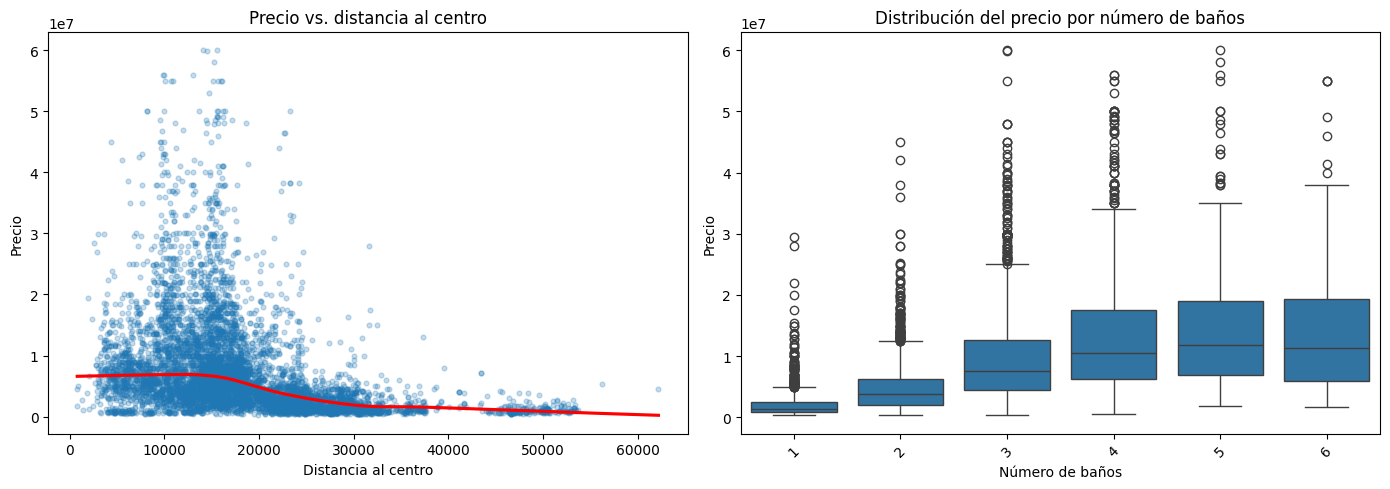

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=df_modelo,
    x="Dist_DCN",
    y="precio",
    lowess=True,
    scatter_kws={"alpha": 0.25, "s": 12},
    line_kws={"color": "red"},
    ax=axes[0]
)
axes[0].set_title("Precio vs. distancia al centro")
axes[0].set_xlabel("Distancia al centro")
axes[0].set_ylabel("Precio")

sns.boxplot(
    data=df_modelo,
    x="banos",
    y="precio",
    ax=axes[1]
)
axes[1].set_title("Distribución del precio por número de baños")
axes[1].set_xlabel("Número de baños")
axes[1].set_ylabel("Precio")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

El grafico de la izquierda muestra una curva Lowess (Locally Weighted Scatterplot Smoothing), la cual nos ayuda a entender si hay o no una relacion no lienal, si la interpretamos podemos ver que en un primer rango de distancia de hasta proximadamente 18000 metros el precio se mantiene, pero eventualmente a medida que la distancia aumenta el valor disminuye, aunque se pueda interpretar esto, no termina de ser tan contundente para afirmar que a mayor distnacia menor precio, pero que si pareciera tener un comportamiento simila a esa regla. 

El grafico de cajas nos dice que a mayor numero de baños, mayor sera el precio, si observamos detenidamente podemos identificar que hay muchas casa con precios mayores a los 4 millones, los cuales pueden empezar a considerarse valores atipicos, esto es ahora lo que analizaremos para determinar que hacer con ellos

### Outliers

Entonces hacemos el análisis sobre el precio

In [39]:
Q1 = df_modelo["precio"].quantile(0.25)
Q3 = df_modelo["precio"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

extremos_precio = df_modelo[ (df_modelo["precio"] < limite_inferior) | (df_modelo["precio"] > limite_superior)]

print(f"Límite inferior: ${limite_inferior:,.0f}")
print(f"Límite superior: ${limite_superior:,.0f}")
print(f"Registros extremos: {len(extremos_precio)}")
print(f"Porcentaje: {len(extremos_precio) / len(df_modelo) * 100:.2f}%")

Límite inferior: $-8,950,000
Límite superior: $21,050,000
Registros extremos: 421
Porcentaje: 6.26%


Bien, tenemos 421 viviendas que represetan el 6.26% de la muesta, vamos a ver cuales son estas observaciones

In [40]:
extremos_precio = df_modelo[df_modelo["precio"] > limite_superior]

extremos_precio[ ["precio", "m2_construidos", "m2_terreno", "NOM_ENT",
                  "NOM_MUN"]].sort_values("precio", ascending=False).head(10)

,precio,m2_construidos,m2_terreno,NOM_ENT,NOM_MUN
6069,60000000.0,941,1002,Ciudad de México,La Magdalena Contreras
2008,60000000.0,600,159,Ciudad de México,Cuajimalpa de Morelos
2658,59900000.0,702,430,Ciudad de México,Cuajimalpa de Morelos
4949,58000000.0,550,1047,Ciudad de México,Coyoacán
656,56000000.0,890,865,México,Naucalpan de Juárez
1025,56000000.0,1000,827,Ciudad de México,Álvaro Obregón
1555,56000000.0,870,865,México,Naucalpan de Juárez
3501,55000000.0,948,1050,Ciudad de México,Álvaro Obregón
4640,55000000.0,650,1000,Ciudad de México,Tlalpan
3299,55000000.0,650,1000,Ciudad de México,Tlalpan


In [41]:
extremos_precio = df_modelo[df_modelo["precio"] > limite_superior].copy()

extremos_precio["precio_m2_calculado"] = ( extremos_precio["precio"] / extremos_precio["m2_construidos"])

extremos_precio[
    [
        "precio",
        "m2_construidos",
        "m2_terreno",
        "precio_m2",
        "precio_m2_calculado",
        "NOM_ENT",
        "NOM_MUN"
    ]
].sort_values("precio", ascending=False).head(15)

,precio,m2_construidos,m2_terreno,precio_m2,precio_m2_calculado,NOM_ENT,NOM_MUN
6069,60000000.0,941,1002,63761.955367,63761.955367,Ciudad de México,La Magdalena Contreras
2008,60000000.0,600,159,100000.000000,100000.000000,Ciudad de México,Cuajimalpa de Morelos
2658,59900000.0,702,430,85327.635328,85327.635328,Ciudad de México,Cuajimalpa de Morelos
4949,58000000.0,550,1047,105454.545455,105454.545455,Ciudad de México,Coyoacán
656,56000000.0,890,865,62921.348315,62921.348315,México,Naucalpan de Juárez
1025,56000000.0,1000,827,56000.000000,56000.000000,Ciudad de México,Álvaro Obregón
1555,56000000.0,870,865,64367.816092,64367.816092,México,Naucalpan de Juárez
3501,55000000.0,948,1050,58016.877637,58016.877637,Ciudad de México,Álvaro Obregón
4640,55000000.0,650,1000,84615.384615,84615.384615,Ciudad de México,Tlalpan
3299,55000000.0,650,1000,84615.384615,84615.384615,Ciudad de México,Tlalpan


El objetivo de la tabla anterior es hacer una inferencia simple del precio por metro cuadrado sobre los metros construidos y observar si han sentido con respecto al precio establecido real. Observamos como muchos de los calculos fallan por demasiado 

In [63]:
df_modelo["precio_m2_calculado"] = (
    df_modelo["precio"] / df_modelo["m2_construidos"]
)

df_modelo["diferencia_pct"] = (
    (df_modelo["precio_m2"] - df_modelo["precio_m2_calculado"])
    / df_modelo["precio_m2_calculado"]
).abs() * 100

print("Diferencia porcentual mediana:")
print(df_modelo["diferencia_pct"].median().round(2), "%")

print("\nPorcentaje de registros con diferencias mayores al 5%:")
print((df_modelo["diferencia_pct"] > 5).mean().round(4) * 100, "%")


Diferencia porcentual mediana:
0.0 %

Porcentaje de registros con diferencias mayores al 5%:
0.0 %


La comprobacion confirma que la variable precio_m2  pareciera haber sido construida como el cociente entre precio y metros construidos ya que no existe una diferencia mayor a 5% entre los valores originales y los calculados, por lo cual lo excluiremos del analisis para ervitar fuga de información.

**Nota:** Despues de haber realizado un análisis más profundo considerando el limite del valor de las propiedas, revisando su ubicación y buscando entender si habia o no una relación entre precios elevados con costos de metros elevados, he tomado la decisión de no borrar ninguno de los valores atipicos y documentarlo al final

### Variables Predictoras

Vamos a quedarnos con la siguiente lista de variables que tienen además de una razón en nuestro análisis previo, un criterio de negocio ligado.

| Variable | Justificación |
|---|---|
| `m2_construidos` | Mayor correlación observada con el precio (0.794). |
| `m2_terreno` | Segunda correlación más alta (0.696); VIF aceptable junto con la superficie construida. |
| `estacionamiento` | Asociación positiva considerable con el precio (0.577). |
| `banos` | Asociación positiva considerable (0.509) y tendencia creciente observada en el boxplot. |
| `Dist_DCN` | Asociación negativa con el precio; Spearman (-0.508) ligera relacion no lineal negativa presente |
| `densidad_ha` | Asociación negativa moderada (-0.311). |
| `poblacion_total` | Asociación negativa moderada (-0.353). |
| `e2sfca_educación_superior_del_sector_publico` | Asociación positiva (0.386), superior a la de `e2sfca_total`. |
| `e2sfca_equipamientos_culturales_del_sector_público` | Asociación positiva moderada (0.310). |
| `NOM_ENT` | Contexto geográfico para distinguir mercados inmobiliarios; se incluye por criterio de negocio. |

## Construcción del Modelo

In [43]:
predictoras = ["m2_construidos","m2_terreno","estacionamiento","banos","Dist_DCN","densidad_ha",
               "poblacion_total","e2sfca_educación_superior_del_sector_publico",
               "e2sfca_equipamientos_culturales_del_sector_público", "NOM_ENT"]

In [44]:
X = df_modelo[predictoras].copy()
y = df_modelo["precio"].copy()

print("Observaciones:", X.shape[0])
print("Número de predictoras:", X.round(2).shape[1])
display(X.head(5).round(2))

Observaciones: 6729
Número de predictoras: 10


,m2_construidos,m2_terreno,estacionamiento,banos,Dist_DCN,densidad_ha,poblacion_total,e2sfca_educación_superior_del_sector_publico,e2sfca_equipamientos_culturales_del_sector_público,NOM_ENT
0,157,90,2,2,19463.04,196.11,1248.13,104.83,28.74,México
1,350,320,3,3,9303.73,9.19,232.42,297.69,52.24,México
2,70,159,2,1,29324.28,87.70,408.03,104.83,28.89,México
3,385,432,3,4,17803.55,26.59,263.55,107.01,32.31,México
4,266,135,3,3,12790.16,419.68,2004.76,228.82,36.62,México


In [45]:
print("Valores nulos:", X.isnull().sum().sum())
print("Valores infinitos:", np.isinf(X.select_dtypes(include="number")).sum().sum())
print("Dimensiones:", X.shape)
print("Objetivo:", y.name)

Valores nulos: 0
Valores infinitos: 0
Dimensiones: (6729, 10)
Objetivo: precio


Ahora si re confirmando nuestros datos, vamos a proceder a hacer la particion de los datos para el entrenamiento y el test

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20, random_state=42)

In [47]:
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Prueba:", X_test.shape, y_test.shape)

Entrenamiento: (5383, 10) (5383,)
Prueba: (1346, 10) (1346,)


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [49]:
var_num= X.select_dtypes(include="number").columns.tolist()
var_cat = ["NOM_ENT"]

In [50]:
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), var_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), var_cat)])

In [51]:
X_train_preparado = preprocesador.fit_transform(X_train)
X_test_preparado = preprocesador.transform(X_test)
print("Entrenamiento preparado:", X_train_preparado.shape)
print("Prueba preparada:", X_test_preparado.shape)

Entrenamiento preparado: (5383, 12)
Prueba preparada: (1346, 12)


### Entrenamiento

In [52]:
from sklearn.linear_model import LinearRegression

In [53]:
modelo_base=LinearRegression()
modelo_base.fit(X_train_preparado, y_train)
y_pred_base = modelo_base.predict(X_test_preparado)

### Evaluacion de las Predictoras

Bien ahora, vamoes a usar el error absoluto medio, el error cuadratico medio y el coeficiente de determinación para evaluar que tan bueno es el modelo

In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [55]:
mae= mean_absolute_error(y_test, y_pred_base)
rmse= np.sqrt(mean_squared_error(y_test, y_pred_base))
r2=r2_score(y_test, y_pred_base)

print(f"MAE: ${mae:,.2f} MXN")
print(f"RMSE: ${rmse:,.2f} MXN")
print(f"R²: {r2:.4f}")

MAE: $2,711,638.80 MXN
RMSE: $4,306,847.10 MXN
R²: 0.7063


Bueno, el coeficiente de determinación (R cuadadro) es bastante alto para ser un modelo incial, sin embargo las metricas del errocuadratico medio estan demasiado elevadas, es decir que estan siendo altamente castigadas por viviendas con precios elevados. No nos vamos a quedar con la duda y procederemos a hacer un análisis igual de Regresion Lineal pero ahora quitando los valores atipicos. Esto es algo que en la practica no es ideal ya que afecta artificialmente la muestra, pero queremos saber si estos outliers son responsables de valores elevados

In [56]:
# Filtrar únicamente el entrenamiento
mask_train = y_train <= limite_superior
X_train_sin_extremos = X_train_preparado[mask_train]
y_train_sin_extremos = y_train[mask_train]

# Entrenar el modelo sin precios extremos
modelo_sin_extremos = LinearRegression()
modelo_sin_extremos.fit(
    X_train_sin_extremos,
    y_train_sin_extremos
)

pred_sin_extremos = modelo_sin_extremos.predict(X_test_preparado)

# Evaluar sobre el conjunto de prueba completo y sobre sus precios no extremos
mask_test = y_test <= limite_superior

def evaluar(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred)
    }

resultados = pd.DataFrame({
    "Modelo original": evaluar(y_test, y_pred_base),
    "Modelo sin extremos": evaluar(y_test, pred_sin_extremos),
    "Modelo sin extremos (prueba filtrada)": evaluar(
        y_test[mask_test],
        pred_sin_extremos[mask_test]
    )
}).T

print(f"Límite superior calculado: ${limite_superior:,.0f} MXN")
print(f"Registros excluidos del entrenamiento: {(~mask_train).sum()}")
print(f"Registros en prueba filtrada: {mask_test.sum()} de {len(y_test)}")

display(resultados.round(4))

Límite superior calculado: $21,050,000 MXN
Registros excluidos del entrenamiento: 340
Registros en prueba filtrada: 1265 de 1346


,MAE,RMSE,R2
Modelo original,2.711639e+06,4.306847e+06,0.7063
Modelo sin extremos,2.628618e+06,4.834696e+06,0.6299
Modelo sin extremos (prueba filtrada),1.849487e+06,2.527851e+06,0.7108


Bien, el cambio no ofrece una mejora significativa, al entrenar sin outliers y evaluar sobre toda la prueba, el RMSE aumentó de $4.31 M a $4.83 M y R² bajó de 0.7063 a 0.6299 y al evaluar el modelo sobre las mismas 1265 viviendas el modelo si mejora, si bien pareciera ser que tiene sentido retirar esos valores del análisis lo que provocariamos seria modificar la muestra de manera artificial y los outliers ya demostramos que no son errores, por ello, conservaremos el conjunto de datos completo como y evaluaremos alternativas de modelado antes de decidir el tratamiento definitivo.

## Random Forest

In [57]:
from sklearn.ensemble import RandomForestRegressor

In [58]:
modelo_rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1)

modelo_rf.fit(X_train_preparado, y_train)
y_pred_rf = modelo_rf.predict(X_test_preparado)

In [59]:
# Calculamos de nuevo las metricas
print(f"MAE:  ${mean_absolute_error(y_test, y_pred_rf):,.2f} MXN")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, y_pred_rf)):,.2f} MXN")
print(f"R²:   {r2_score(y_test, y_pred_rf):.4f}")

MAE:  $2,008,690.56 MXN
RMSE: $3,700,472.75 MXN
R²:   0.7832


Bien, las 3 metricas mejoraron, con esto ya tenemos evidencia de que Random Forest captura relaciones no lineales presentes en los datos, por ahora es nuestro candidato para continuar la evaluación del modelo.

Bien, en nuestro análisis anterior haciendo uso de correlogramas pudimos observar cuales eran las variables más importantes en la regresion lineal, ahora haremos ese mismo análisis pero para distinguir cuales son las variables de mayor importancia en el Random forest

In [60]:
importancias = pd.Series(modelo_rf.feature_importances_,
                         index=preprocesador.get_feature_names_out()).sort_values(ascending=False)

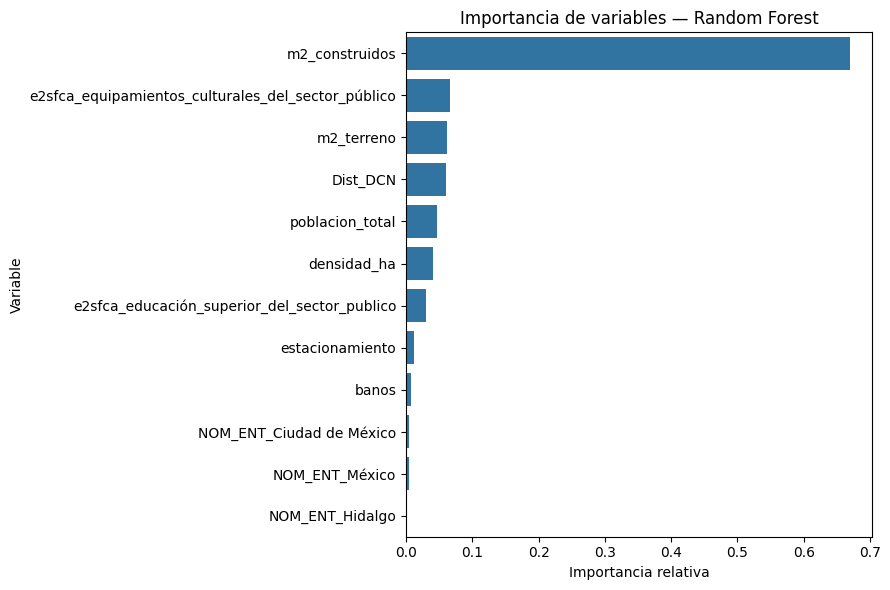

In [61]:
importancias_originales = importancias.copy()
importancias_originales.index = [
    nombre.replace("num__", "").replace("cat__", "")
    for nombre in importancias_originales.index
]

plt.figure(figsize=(9, 6))
sns.barplot( x=importancias_originales.values, y=importancias_originales.index)

plt.title("Importancia de variables — Random Forest")
plt.xlabel("Importancia relativa")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

De nuevo, al igual que en la regresion lineal, la variable de metros cuadrados construidos figura como la más importante, esta vez los equipamientos culturales tomo mucho más relevancia. Tambien podemos distringuir que la entidad federativa, los baños y el estacionamiento no tienen tanto impacto, a pesar de ser algo que intuitivamente diria que si

Ahora vamos a contrastar en un grafico las predicciones con los valores reales para observar que tan bien o mal lo esta haciendo el modelo

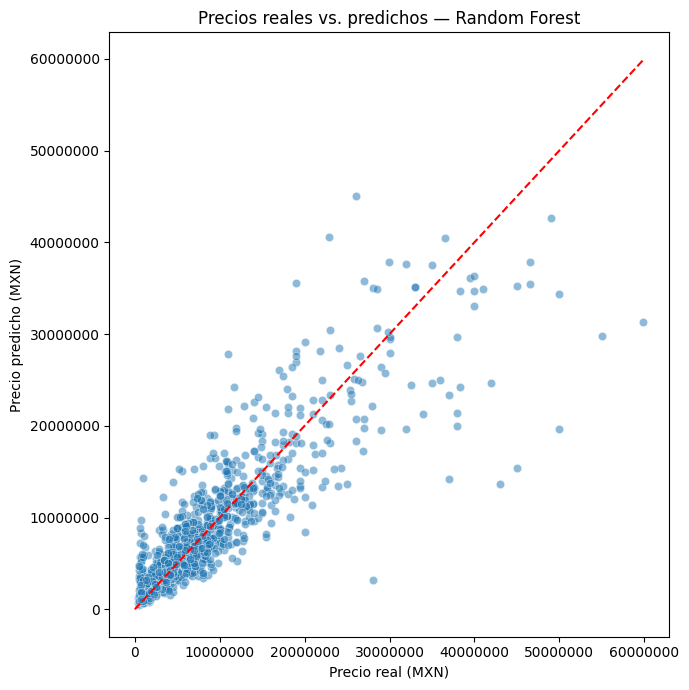

In [62]:
plt.figure(figsize=(7, 7))

sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.5)

limite = max(y_test.max(), y_pred_rf.max())
plt.plot([0, limite], [0, limite], "--", color="red")

plt.title("Precios reales vs. predichos — Random Forest")
plt.xlabel("Precio real (MXN)")
plt.ylabel("Precio predicho (MXN)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

**Conclusión:** El modelo funciona muy bien con viviendas de hasta 30 millones de pesos aproximadamente, a partir de ahi empeiza a ser muy impreciso, de hecho el modelo muestra relativamente pocas predicciones que van entre los 35 y 50 millones, a diferencia de los valores reales que pueden llegar hasta los 60 millones, significa que el modelo esta subestimando los precios. Esto indica que, si bien el modelo de Random forest mejora las metricas, su precision se ve limitada ante viviendas con valores muy altos